# Stacking SPHEREx Infrared Photometry at HETDEX Lyman-Alpha Emitter Positions

**Author(s):** Parag Chettri (UG Student) with Prof. Donghui Jeong, Department of Astronomy & Astrophysics, Pennsylvania State University

**Date:** 27th August 2026 (first run), updated 23rd November 2026 for SPHEREx DR1

When we first started this project, the question we wanted to answer was simple: what does the average Lyman-alpha emitter (LAE) look like in the infrared, where its rest-frame optical emission lines live? HETDEX gives us spectroscopic redshifts for tens of thousands of LAEs at $z \sim 2-3$, but its VIRUS spectrograph only reaches 3500-5500 Å, which means [O II] 3727, [O III] 5007 and Hα 6563 are completely out of reach. At these redshifts, those lines land between roughly 1.3 and 2.3 µm in the observed frame, which is exactly where SPHEREx operates.

This notebook stacks SPHEREx spectral-image photometry at the positions of HETDEX PDR1 LAEs (Mentuch Cooper et al. 2023), shifts every measurement into the rest frame, and asks whether any of those three lines can be recovered statistically. Additionally, the pipeline in this repository pulls every SPHEREx exposure covering each LAE directly from the IRSA archive, so the whole analysis can be rerun whenever SPHEREx publishes a new data release.

## Analysis Steps

1. Loads a cache of 39,403 LAEs with SPHEREx coverage from DR1 and QR3. That is essentially the full high-confidence HETDEX LAE sample; my first run in 2026 only had 20,268, about half.
2. Restricts the stack to the 35,673 galaxies covered by all six SPHEREx detectors (D1-D6). In the 2026 run, the number of bands covering a source correlated strongly with its brightness (Kruskal-Wallis $p = 8.8\times10^{-66}$), so mixing band counts biased any cross-band comparison. With near-complete coverage that effect is largely gone, but the cut still guarantees coverage at all three target lines.
3. Builds two stacks with a shared per-galaxy normalization: one with the raw image flux and one with the SPHEREx zodiacal-light (ZODI) model subtracted.
4. Tests each line with 1000 bootstrap resamples and with two null tests (an off-line scan and a redshift shuffle). At this sample size, the null tests decide the verdict.

## Result in brief

None of the three lines is detected. The bootstrap flags all three at $p < 0.001$, but that is a property of the sample size, not of the lines: with 35,673 galaxies the stack is so stable under resampling that any fixed residual looks significant. The null tests show what those residuals are. The [O II] signal gets *stronger* when the redshifts are shuffled, so it is not tied to the galaxies' rest frame; [O III] is ordinary; and Hα shows a marginal excess (4% of off-line positions as high, 2.6 shuffle-sigma) that stays below the detection threshold. Hα is also the line that gave a hint in the 198-galaxy pilot, so it is worth watching, not claiming.

The more useful result is what did not change. With 63 times more galaxies than the 2026 run, the $3\sigma$ upper limits on the line-to-continuum ratio (0.37, 0.28 and 0.13 for [O II], [O III] and Hα) are no tighter than before, even though the 2026 limits were computed with a more optimistic method. The stack is now limited by systematics (zodiacal light is about 85% of the raw signal, and its model residuals and the continuum shape set the floor), not by the number of galaxies.

## Requirements

- `data/sed_cache_full.pkl` (default): per-galaxy `(wav_rest_um, flux_raw, flux_clean)` arrays keyed by HETDEX `source_id`. A fresh one is built by `./run_pipeline.sh`, which queries every SPHEREx exposure in the IRSA archive at each LAE position.
- The HETDEX PDR1 catalog, downloaded automatically from Zenodo into `data/` on first run.
- Four environment variables override the defaults, which is how the pipeline's analysis job runs this notebook: `SPHEREX_CACHE` (cache path), `SPHEREX_OUTDIR` (where figures, the bootstrap cache, and `summary.json` go), `SPHEREX_N_BOOTSTRAP` and `SPHEREX_N_SHUFFLE`.
- For the DR1 sample, the bootstrap takes about 30 minutes at 1000 resamples and the null tests about 10. Bootstrap results are cached in the output directory, keyed to the input cache and resample count, so an interrupted run resumes and a new cache never reuses stale results.


## Imports

In [1]:
import json
import hashlib
import pickle
import os
import datetime
import urllib.request

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy import stats
from astropy.table import Table

import logging
logging.getLogger("astropy").setLevel(logging.ERROR)

## Configuration

In [2]:
# Paths can be overridden from the environment (see run_pipeline.sh)
CACHE_FILE   = os.environ.get("SPHEREX_CACHE", "data/sed_cache_full.pkl")
CATALOG_FILE = "data/hetdex_sc1_v3.2.ecsv"
OUTDIR = os.environ.get("SPHEREX_OUTDIR", "runs/local")
os.makedirs(OUTDIR, exist_ok=True)

SPHEREX_BLUE_OBS = 0.75   # um, D1 blue edge
SPHEREX_RED_OBS  = 5.00   # um, D6 red edge
GAP_THRESHOLD    = 0.02   # um -- gap separating detector bands

N_BINS       = 80     # stacking grid bins
N_MIN_RATIO  = 5      # minimum galaxies per bin
N_BOOTSTRAP  = int(os.environ.get("SPHEREX_N_BOOTSTRAP", 1000))   # resamples per line
CLIP_SIGMA   = 5.0    # MAD-based sigma for outlier clipping
CLIP_ITERS   = 3

# Line extraction windows (validated in prior runs)
LINE_HALF   = 0.015   # um -- line integration half-window (~2 SPHEREx resel)
CONT_INNER  = 0.040   # um -- continuum sideband inner edge
CONT_OUTER  = 0.130   # um -- continuum sideband outer edge
EDGE_BUFFER = 0.02    # um -- safety margin from detector band edge

LINES_REACHABLE = {
    "OII_3727":  0.3727,
    "OIII_5007": 0.5007,
    "Ha_6563":   0.6563,
}

STABILITY_THRESHOLD = 0.15   # 15% raw-vs-clean stability criterion
MIN_SNR             = 2.0    # minimum |SNR| for a stability verdict

# Null tests (see "Null tests" below). These set the detection verdict.
N_SHUFFLE      = int(os.environ.get("SPHEREX_N_SHUFFLE", 20))   # redshift shuffles
SHUFFLE_SEED   = 7
N_OFFLINE      = 400    # wavelengths sampled in the off-line scan
DETECT_OFFLINE = 0.01   # detection: under 1% of off-line positions as high ...
DETECT_SHUFFLE = 5.0    # ... and at least 5 shuffle-sigma above the shuffles
HINT_OFFLINE   = 0.05   # hint: a weaker version of both
HINT_SHUFFLE   = 2.0

## Load the cache and catalog

In [3]:
with open(CACHE_FILE, "rb") as fh:
    cache = pickle.load(fh)
print(f"Loaded {len(cache)} galaxies from {os.path.basename(CACHE_FILE)}")

source_ids = list(cache.keys())
all_wavs   = [cache[sid][0] for sid in source_ids]
all_raws   = [cache[sid][1] for sid in source_ids]
all_cleans = [cache[sid][2] for sid in source_ids]

# Catalog for redshifts
if not os.path.exists(CATALOG_FILE):
    os.makedirs(os.path.dirname(CATALOG_FILE), exist_ok=True)
    print("Downloading HETDEX catalog ...")
    urllib.request.urlretrieve(
        "https://zenodo.org/records/7448504/files/hetdex_sc1_v3.2.ecsv?download=1",
        CATALOG_FILE)
cat = Table.read(CATALOG_FILE, format="ascii.ecsv")
id_to_z = {int(row["source_id"]): float(row["z_hetdex"]) for row in cat}

zs = np.array([id_to_z.get(sid, np.nan) for sid in source_ids])
valid_z = np.sum(np.isfinite(zs))
print(f"Redshifts recovered: {valid_z}/{len(zs)}")

n_pairs = [len(w) for w in all_wavs]
print(f"Pairs per galaxy -- mean: {np.mean(n_pairs):.1f}  "
      f"median: {np.median(n_pairs):.0f}  max: {np.max(n_pairs)}")

Loaded 39403 galaxies from sed_cache_full.pkl


Redshifts recovered: 39403/39403
Pairs per galaxy -- mean: 53.7  median: 54  max: 54


## Core utilities

Band splitting, MAD-based sigma clipping, and the stacking function. Each galaxy gets one normalization constant (the sigma-clipped median of its raw flux), and that same constant is applied to both the raw and ZODI-subtracted stacks. Normalizing the two stacks independently was the source of the sign flips I ran into in early versions of this pipeline.

In [4]:
def split_into_bands(w, gap=GAP_THRESHOLD):
    order = np.argsort(w)
    w_s = w[order]
    breaks = np.where(np.diff(w_s) > gap)[0]
    band_ids = np.zeros(len(w_s), dtype=int)
    for b in breaks:
        band_ids[b + 1:] += 1
    return order, band_ids


def n_bands_for(w, f):
    finite = np.isfinite(w) & np.isfinite(f)
    if finite.sum() < 3:
        return 0
    _, bids = split_into_bands(w[finite])
    return len(np.unique(bids))


def sigma_clip_mask(arr, sigma=CLIP_SIGMA, iters=CLIP_ITERS):
    mask = np.isfinite(arr)
    for _ in range(iters):
        if mask.sum() < 3:
            break
        med = np.median(arr[mask])
        mad = np.median(np.abs(arr[mask] - med))
        sig = mad * 1.4826 if mad > 0 else np.std(arr[mask])
        if sig == 0:
            break
        new_mask = mask & (np.abs(arr - med) <= sigma * sig)
        if new_mask.sum() == mask.sum():
            break
        mask = new_mask
    return mask


def compute_norms(all_raws):
    """One normalization constant per galaxy, from sigma-clipped raw median."""
    norms = []
    for f in all_raws:
        finite = f[np.isfinite(f)]
        if len(finite) == 0:
            norms.append(np.nan)
            continue
        keep = sigma_clip_mask(finite)
        med = np.median(finite[keep]) if keep.sum() > 0 else np.nan
        norms.append(med if (np.isfinite(med) and med != 0) else np.nan)
    return np.array(norms)


def make_stack(wavs, fluxes, norms, label=""):
    """Sigma-clipped median stack with shared per-galaxy normalization."""
    med = np.full(N_BINS, np.nan)
    sem = np.full(N_BINS, np.nan)
    cnt = np.zeros(N_BINS, dtype=int)
    for i, wg in enumerate(wav_grid):
        vals = []
        for w, f, norm in zip(wavs, fluxes, norms):
            if not np.isfinite(norm) or norm == 0:
                continue
            m = np.abs(w - wg) < dw
            if not m.any():
                continue
            v = (f[m] / norm)
            vals.extend(v[np.isfinite(v)].tolist())
        if len(vals) < N_MIN_RATIO:
            continue
        v = np.array(vals)
        keep = sigma_clip_mask(v)
        if keep.sum() < N_MIN_RATIO:
            continue
        vc = v[keep]
        med[i] = np.median(vc)
        sem[i] = np.std(vc) / np.sqrt(len(vc))
        cnt[i] = len(vc)
    good = np.isfinite(med) & (cnt >= N_MIN_RATIO)
    if label:
        print(f"  {label}: {good.sum()}/{N_BINS} bins with data")
    return med, sem, cnt, good

## Subset selection: six-band sample and brightness-matched control

Of course, it would be tempting to stack every galaxy at once. In the 2026 run that was a real problem: with partial coverage, galaxies covered by more SPHEREx bands were systematically brighter, so a mixed stack quietly averaged over different populations. With DR1 and QR3 nearly every LAE is covered by all six detectors, so that selection effect is largely gone and the six-band cut now keeps about 90% of the sample. I keep the cut because it guarantees complete coverage at all three target lines.

One caveat: the band count here comes from gaps in each galaxy's rest-frame wavelengths (`split_into_bands`), not from the fetch. When two neighboring detectors' strips land close together in wavelength, they merge into one segment. That is why 35,673 galaxies count as six-band here, even though the fetch measured all six detectors for 39,419. Because rest-frame gaps shrink with $1+z$, the dropped galaxies lean slightly toward higher redshift.

The control sample contains galaxies with two to four bands whose median flux falls within the interquartile range of the six-band sample. See Figure 4 for why this control means less in DR1 than it did in 2026.


In [5]:
idx_6band   = []
idx_control = []

bright_6 = []
for i in range(len(source_ids)):
    nb = n_bands_for(all_wavs[i], all_raws[i])
    if nb == 6:
        finite_f = all_raws[i][np.isfinite(all_raws[i])]
        if len(finite_f) > 0:
            bright_6.append(np.median(finite_f))
            idx_6band.append(i)

bright_lo = np.nanpercentile(bright_6, 25)
bright_hi = np.nanpercentile(bright_6, 75)
print(f"6-band subset: N={len(idx_6band)}")
print(f"6-band brightness IQR: [{bright_lo:.4f}, {bright_hi:.4f}]")

for i in range(len(source_ids)):
    nb = n_bands_for(all_wavs[i], all_raws[i])
    if nb not in [2, 3, 4]:
        continue
    finite_f = all_raws[i][np.isfinite(all_raws[i])]
    if len(finite_f) == 0:
        continue
    med_f = np.median(finite_f)
    if bright_lo <= med_f <= bright_hi:
        idx_control.append(i)

print(f"Brightness-matched control: N={len(idx_control)} (2-4 bands, same flux IQR)")

zs_6  = zs[idx_6band]
z_min = float(np.nanmin(zs_6))
z_max = float(np.nanmax(zs_6))
print(f"\n6-band redshift range: [{z_min:.3f}, {z_max:.3f}]  mean z={np.nanmean(zs_6):.3f}")


def make_subset(idxs):
    return ([all_wavs[i] for i in idxs],
            [all_raws[i] for i in idxs],
            [all_cleans[i] for i in idxs])


wav_6, raw_6, cln_6       = make_subset(idx_6band)
wav_ctl, raw_ctl, cln_ctl = make_subset(idx_control)


6-band subset: N=35673
6-band brightness IQR: [0.1410, 0.1914]


Brightness-matched control: N=464 (2-4 bands, same flux IQR)

6-band redshift range: [1.888, 3.515]  mean z=2.515


## Stacking grid

The grid spans the full rest-frame range SPHEREx reaches for this sample's redshift distribution.

In [6]:
WAV_MIN = SPHEREX_BLUE_OBS / (1 + z_max)
WAV_MAX = SPHEREX_RED_OBS  / (1 + z_min)
wav_grid = np.linspace(WAV_MIN, WAV_MAX, N_BINS)
dw       = wav_grid[1] - wav_grid[0]
print(f"Stack grid: {WAV_MIN:.4f}–{WAV_MAX:.4f} um  "
      f"({N_BINS} bins, dw={dw:.4f} um)")

Stack grid: 0.1661–1.7312 um  (80 bins, dw=0.0198 um)


## Raw and ZODI-subtracted stacks

The ZODI fraction, $f_{\rm ZODI} = 1 - F_{\rm clean}/F_{\rm raw}$, is also a sanity check: a negative value would mean the normalization is broken.

In [7]:
norms_6 = compute_norms(raw_6)
print(f"Valid normalization constants: {np.sum(np.isfinite(norms_6))}/{len(norms_6)}")

print("Running ZODI-agnostic stack ...")
med_raw, sem_raw, n_raw, good_raw = make_stack(wav_6, raw_6, norms_6, "ZODI-agnostic")

print("Running ZODI-integrated stack ...")
med_cln, sem_cln, n_cln, good_cln = make_stack(wav_6, cln_6, norms_6, "ZODI-integrated")

good_both = good_raw & good_cln

# ZODI contamination fraction
good_zodi = good_both & (med_raw != 0)
zodi_frac = 1.0 - med_cln[good_zodi] / med_raw[good_zodi]
zodi_global = np.nanmedian(zodi_frac)
print(f"\nGlobal ZODI contamination fraction: {zodi_global:.3f}")

if zodi_global < -0.05:
    print("WARNING: negative ZODI fraction -- check normalization.")
else:
    print("ZODI fraction positive and physical. Stacks consistent.")

# Print regional breakdown
edges = np.linspace(WAV_MIN, WAV_MAX, 7)
wg_z  = wav_grid[good_zodi]
print(f"\n{'Region (um)':22s}  {'ZODI fraction':>14s}")
for lo, hi in zip(edges[:-1], edges[1:]):
    mask = (wg_z >= lo) & (wg_z < hi)
    if mask.sum() > 0:
        print(f"  {lo:.3f}–{hi:.3f}           {np.nanmedian(zodi_frac[mask]):>14.3f}")

Valid normalization constants: 35673/35673
Running ZODI-agnostic stack ...


  ZODI-agnostic: 80/80 bins with data
Running ZODI-integrated stack ...


  ZODI-integrated: 80/80 bins with data

Global ZODI contamination fraction: 0.851
ZODI fraction positive and physical. Stacks consistent.

Region (um)              ZODI fraction
  0.166–0.427                    0.841
  0.427–0.688                    0.847
  0.688–0.949                    0.811
  0.949–1.209                    0.847
  1.209–1.470                    0.887
  1.470–1.731                    0.912


## Figure 1: stacked spectrum

If a line were genuinely detected, the clean stack would show a bump above its local continuum at the marked wavelength, and the raw and clean curves would share the same shape apart from the zodiacal offset.

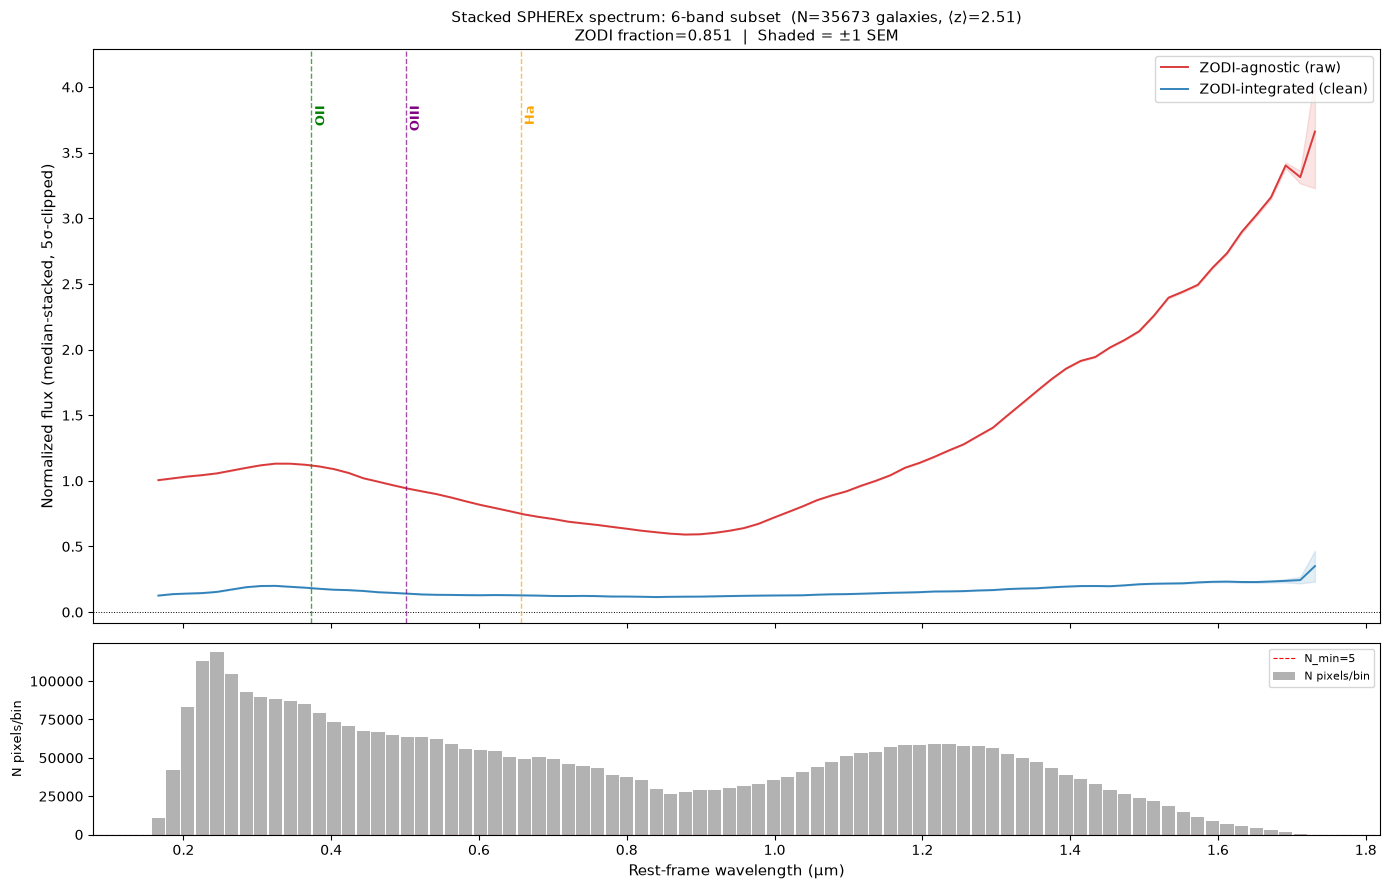

Saved: stack_full_spectrum.png


In [8]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True,
                          gridspec_kw={"height_ratios": [3, 1]})

ax = axes[0]
ax.plot(wav_grid[good_raw], med_raw[good_raw],
        color="tab:red", lw=1.4, alpha=0.9, label="ZODI-agnostic (raw)")
ax.fill_between(wav_grid[good_raw],
                 med_raw[good_raw] - sem_raw[good_raw],
                 med_raw[good_raw] + sem_raw[good_raw],
                 color="tab:red", alpha=0.12)
ax.plot(wav_grid[good_cln], med_cln[good_cln],
        color="tab:blue", lw=1.4, alpha=0.9, label="ZODI-integrated (clean)")
ax.fill_between(wav_grid[good_cln],
                 med_cln[good_cln] - sem_cln[good_cln],
                 med_cln[good_cln] + sem_cln[good_cln],
                 color="tab:blue", alpha=0.12)
ax.axhline(0, color="black", lw=0.7, ls=":")

line_colors = {"OII_3727": "green", "OIII_5007": "purple", "Ha_6563": "orange"}
for name, lam in LINES_REACHABLE.items():
    if WAV_MIN <= lam <= WAV_MAX:
        ax.axvline(lam, color=line_colors[name], lw=1.0, ls="--", alpha=0.7)
        ax.text(lam + 0.005, ax.get_ylim()[1] * 0.90,
                name.split("_")[0], fontsize=9,
                color=line_colors[name], rotation=90, va="top", fontweight="bold")

ax.set_ylabel("Normalized flux (median-stacked, 5σ-clipped)", fontsize=11)
ax.set_title(
    f"Stacked SPHEREx spectrum: 6-band subset  "
    f"(N={len(wav_6)} galaxies, \u27e8z\u27e9={np.nanmean(zs_6):.2f})\n"
    f"ZODI fraction={zodi_global:.3f}  |  Shaded = \u00b11 SEM",
    fontsize=11)
ax.legend(loc="upper right", fontsize=10)

ax2 = axes[1]
ax2.bar(wav_grid[good_raw], n_raw[good_raw],
        width=dw * 0.9, color="tab:gray", alpha=0.6, label="N pixels/bin")
ax2.axhline(N_MIN_RATIO, color="red", lw=0.8, ls="--", label=f"N_min={N_MIN_RATIO}")
ax2.set_xlabel("Rest-frame wavelength (\u00b5m)", fontsize=11)
ax2.set_ylabel("N pixels/bin", fontsize=9)
ax2.legend(fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(OUTDIR, "stack_full_spectrum.png"), dpi=150, bbox_inches="tight")
plt.show()
print("Saved: stack_full_spectrum.png")

## Line extraction

`check_reachability` skips lines that fall outside SPHEREx's range for this redshift distribution and flags lines that sit near the D1 blue edge. That check exists because an earlier version of this pipeline reported a CIV "detection" that turned out to be the band edge leaking into the line window. Both stacks are measured on the same set of valid bins.

In [9]:
def check_reachability(lam, z_min, z_max):
    if lam * (1 + z_max) < SPHEREX_BLUE_OBS:
        return "unreachable", f"obs={lam*(1+z_max):.3f} < blue limit"
    if lam * (1 + z_min) > SPHEREX_RED_OBS:
        return "unreachable", f"obs={lam*(1+z_min):.3f} > red limit"
    d1_edge = SPHEREX_BLUE_OBS / (1 + z_max)
    if abs(lam - d1_edge) < (LINE_HALF + EDGE_BUFFER):
        return "edge_caution", f"near D1 edge at z_max ({d1_edge:.4f} um)"
    return "reachable", ""


def extract_line(stack_med, good, lam0):
    wg = wav_grid[good]
    sm = stack_med[good]
    in_line = np.abs(wg - lam0) < LINE_HALF
    in_cont = (((wg > lam0 + CONT_INNER) & (wg < lam0 + CONT_OUTER)) |
               ((wg < lam0 - CONT_INNER) & (wg > lam0 - CONT_OUTER)))
    if in_line.sum() == 0:
        return np.nan, np.nan, np.nan, np.nan
    cont = np.nanmedian(sm[in_cont]) if in_cont.sum() >= 3 else np.nanmedian(sm)
    step = wg[1] - wg[0] if len(wg) > 1 else LINE_HALF * 2
    lf   = np.nansum(sm[in_line] - cont) * step
    lc   = lf / (abs(cont) * 2 * LINE_HALF) if cont != 0 else np.nan
    noise = np.nanstd(sm[in_cont]) if in_cont.sum() >= 3 else np.nan
    snr   = (lf / (noise * np.sqrt(in_line.sum()) * step)
             if (np.isfinite(noise) and noise > 0) else np.nan)
    return lf, cont, lc, snr

## Bootstrap significance test

A single-stack SNR can be misleading at this depth, so I resample the six-band galaxies with replacement 1000 times, re-stack, and re-measure each line. The one-sided $p$-value is the fraction of resamples with SNR $\le 0$. Results are written to disk after each line, so the cell can be safely interrupted and re-run.

One caveat I only ran into with DR1: the bootstrap asks whether the line SNR stays positive when galaxies are resampled. At $N = 565$ that was the right question, because galaxy-to-galaxy noise dominated the stack. At $N \approx 35{,}000$ the stack barely moves under resampling, so any fixed residual (a real line, curvature in the continuum, or a zodiacal-model systematic) comes out at $p = 0$. I still report the bootstrap, but the detection verdict now comes from the null tests below.


In [10]:
# Cache name encodes the input cache and resample count, so a new data
# release or a different N_BOOTSTRAP never picks up stale results
_cache_tag = (f"{os.path.abspath(CACHE_FILE)}|{os.path.getsize(CACHE_FILE)}"
              f"|{int(os.path.getmtime(CACHE_FILE))}|{N_BOOTSTRAP}")
_cache_id = hashlib.md5(_cache_tag.encode()).hexdigest()[:10]
BOOT_CACHE_FILE = os.path.join(OUTDIR, f"bootstrap_cache_{_cache_id}.pkl")
import os, pickle as _pkl

rng = np.random.default_rng(42)

# Resumable: load any previously completed lines
if os.path.exists(BOOT_CACHE_FILE):
    with open(BOOT_CACHE_FILE, "rb") as _fh:
        bootstrap_results = _pkl.load(_fh)
    print(f"Loaded {len(bootstrap_results)} previously completed bootstrap lines")
else:
    bootstrap_results = {}

def bin_index(wavs, fluxes, norms):
    """Pre-sort every galaxy's normalized pixels into the stacking bins once.

    For each bin, returns (values, galaxy index). A bootstrap resample then
    only needs each galaxy's draw count: repeating its values that many times
    gives exactly the pixel list make_stack would build from the resampled
    galaxy list, so the median stack is identical but costs milliseconds
    instead of a Python loop over every galaxy and bin."""
    per_bin = []
    for wg in wav_grid:
        vals, gal = [], []
        for g, (w, f, norm) in enumerate(zip(wavs, fluxes, norms)):
            if not np.isfinite(norm) or norm == 0:
                continue
            m = np.abs(w - wg) < dw
            if not m.any():
                continue
            v = f[m] / norm
            v = v[np.isfinite(v)]
            vals.append(v); gal.append(np.full(len(v), g))
        per_bin.append((np.concatenate(vals) if vals else np.array([]),
                        np.concatenate(gal) if gal else np.array([], int)))
    return per_bin


def make_stack_counts(per_bin, counts):
    """make_stack for a resample described by per-galaxy draw counts."""
    med = np.full(N_BINS, np.nan)
    cnt = np.zeros(N_BINS, dtype=int)
    for i, (vals, gal) in enumerate(per_bin):
        if len(vals) == 0:
            continue
        v = np.repeat(vals, counts[gal])
        if len(v) < N_MIN_RATIO:
            continue
        keep = sigma_clip_mask(v)
        if keep.sum() < N_MIN_RATIO:
            continue
        med[i] = np.median(v[keep])
        cnt[i] = keep.sum()
    good = np.isfinite(med) & (cnt >= N_MIN_RATIO)
    return med, None, cnt, good


def bootstrap_stack_snr(wavs, raws, cleans, norms, lam0, n_boot=N_BOOTSTRAP,
                        bins_raw=None, bins_cln=None):
    # Same random draws as the original per-galaxy implementation, so the
    # p-values are unchanged; only the stacking is vectorized.
    snrs_raw, snrs_cln = [], []
    n = len(wavs)
    for _ in range(n_boot):
        idx_b = rng.integers(0, n, size=n)
        counts = np.bincount(idx_b, minlength=n)
        mr, _, _, gr = make_stack_counts(bins_raw, counts)
        mc, _, _, gc = make_stack_counts(bins_cln, counts)
        gb = gr & gc
        _, _, _, snr_r = extract_line(mr, gb, lam0)
        _, _, _, snr_c = extract_line(mc, gb, lam0)
        snrs_raw.append(snr_r if np.isfinite(snr_r) else 0.0)
        snrs_cln.append(snr_c if np.isfinite(snr_c) else 0.0)
    return np.array(snrs_raw), np.array(snrs_cln)


import time as _time
_t0 = _time.time()
bins_raw_6 = bin_index(wav_6, raw_6, norms_6)
bins_cln_6 = bin_index(wav_6, cln_6, norms_6)
print(f"Binned {len(wav_6)} galaxies in {_time.time() - _t0:.0f} s")

print(f"Running {N_BOOTSTRAP} bootstrap resamples per line ...")
print(f"N={len(wav_6)} galaxies -- results saved after each line completes.")
print(f"Safe to interrupt and re-run: already-done lines are skipped.\n")

for name, lam in LINES_REACHABLE.items():
    # Skip if already done
    if name in bootstrap_results:
        res = bootstrap_results[name]
        det = ("DETECTION" if res["p_cln"] < 0.05
               else "marginal" if res["p_cln"] < 0.10 else "non-detect")
        print(f"  {name}: already done  "
              f"SNR clean={res['median_snr_cln']:.2f}  "
              f"p={res['p_cln']:.3f}  [{det}]")
        continue

    status, detail = check_reachability(lam, z_min, z_max)
    if status == "unreachable":
        print(f"  {name}: UNREACHABLE ({detail})")
        continue

    print(f"  Bootstrapping {name} ...", end=" ", flush=True)
    _t0 = _time.time()
    snrs_r, snrs_c = bootstrap_stack_snr(wav_6, raw_6, cln_6, norms_6, lam,
                                         bins_raw=bins_raw_6, bins_cln=bins_cln_6)
    p_raw = float(np.mean(snrs_r <= 0))
    p_cln = float(np.mean(snrs_c <= 0))

    bootstrap_results[name] = dict(
        lam=lam, status=status,
        snrs_raw=snrs_r, snrs_cln=snrs_c,
        median_snr_raw=float(np.median(snrs_r)),
        median_snr_cln=float(np.median(snrs_c)),
        p_raw=p_raw, p_cln=p_cln,
    )

    # Save immediately -- if kernel dies, this line is preserved
    with open(BOOT_CACHE_FILE, "wb") as _fh:
        _pkl.dump(bootstrap_results, _fh)

    det = ("DETECTION" if p_cln < 0.05
           else "marginal" if p_cln < 0.10 else "non-detect")
    print(f"SNR clean={np.median(snrs_c):.2f}  p={p_cln:.3f}  [{det}]  "
          f"({(_time.time() - _t0) / 60:.1f} min)")

print("\nAll lines complete. Results in:", os.path.basename(BOOT_CACHE_FILE))


Loaded 3 previously completed bootstrap lines


Binned 35673 galaxies in 21 s
Running 1000 bootstrap resamples per line ...
N=35673 galaxies -- results saved after each line completes.
Safe to interrupt and re-run: already-done lines are skipped.

  OII_3727: already done  SNR clean=1.07  p=0.000  [DETECTION]
  OIII_5007: already done  SNR clean=0.45  p=0.000  [DETECTION]
  Ha_6563: already done  SNR clean=1.38  p=0.000  [DETECTION]

All lines complete. Results in: bootstrap_cache_bbaaa5cb85.pkl


## Figure 2: bootstrap SNR distributions

Top row: raw stack. Bottom row: ZODI-subtracted stack. A real detection would sit clearly to the right of the dashed SNR = 0 line in the bottom row.

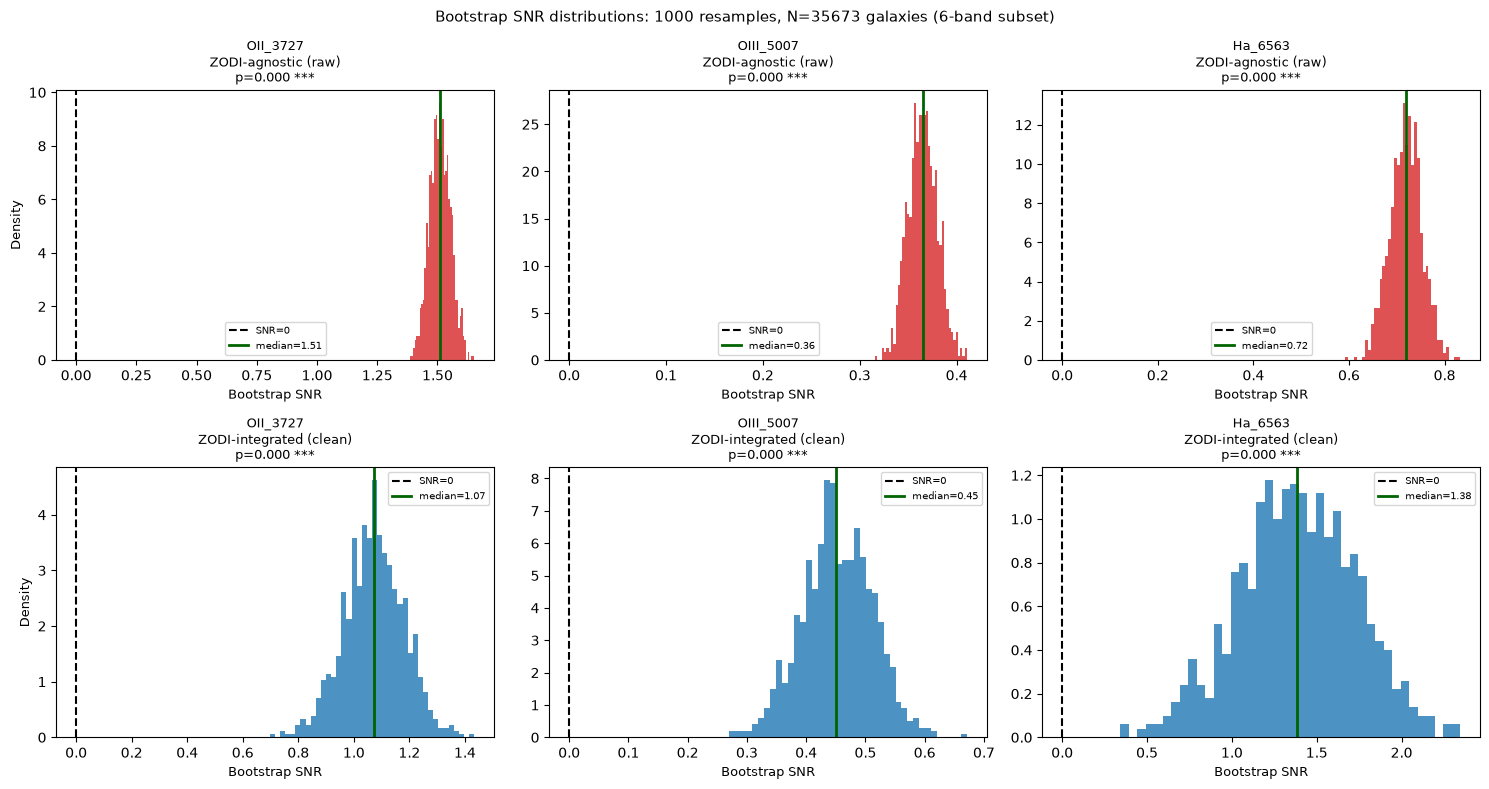

Saved: bootstrap_snr_full.png


In [11]:
n_lines = len(bootstrap_results)
fig, axes = plt.subplots(2, n_lines, figsize=(5 * n_lines, 8))
if n_lines == 1:
    axes = axes.reshape(2, 1)

for col, (name, res) in enumerate(bootstrap_results.items()):
    for row, (snrs, stack_label, color) in enumerate([
        (res["snrs_raw"], "ZODI-agnostic (raw)", "tab:red"),
        (res["snrs_cln"], "ZODI-integrated (clean)", "tab:blue"),
    ]):
        ax = axes[row][col]
        ax.hist(snrs, bins=40, color=color, alpha=0.8, density=True)
        ax.axvline(0, color="black", lw=1.5, ls="--", label="SNR=0")
        ax.axvline(np.median(snrs), color="darkgreen", lw=2.0,
                   label=f"median={np.median(snrs):.2f}")
        p = res["p_raw"] if row == 0 else res["p_cln"]
        sig = ("***" if p < 0.001 else "**" if p < 0.01
               else "*" if p < 0.05 else "~" if p < 0.10 else "ns")
        ax.set_title(f"{name}\n{stack_label}\np={p:.3f} {sig}", fontsize=9)
        ax.set_xlabel("Bootstrap SNR", fontsize=9)
        if col == 0:
            ax.set_ylabel("Density", fontsize=9)
        ax.legend(fontsize=7)

plt.suptitle(f"Bootstrap SNR distributions: {N_BOOTSTRAP} resamples, "
             f"N={len(wav_6)} galaxies (6-band subset)", fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(OUTDIR, "bootstrap_snr_full.png"), dpi=150, bbox_inches="tight")
plt.show()
print("Saved: bootstrap_snr_full.png")

## Null tests: is the signal tied to the rest frame?

The question the bootstrap cannot answer at this sample size is whether a positive residual at a line wavelength actually belongs to the galaxies. I use two tests for that.

1. **Off-line scan.** I measure the same line statistic at about 350 wavelengths along the clean stack where no line is expected. A real line should stand out from that distribution, while continuum curvature shows up everywhere.
2. **Redshift shuffle.** Every galaxy is given another galaxy's redshift and the clean stack is rebuilt. This smears out anything at a fixed rest wavelength, while structure fixed in the observed frame (zodiacal residuals, detector edges) survives. A real line should sit well above the shuffled stacks.

A line counts as detected only if fewer than 1% of off-line positions reach its SNR **and** it sits at least 5 shuffle-sigma above the shuffled stacks. Meeting a weaker version of both (5% and 2 sigma) is reported as a hint. I checked these tests with injections on mock catalogs: an injected [O II] line at SNR ≈ 2.7 passed both easily (no off-line position as high, 61 shuffle-sigma), while the same mock without the line did not. With three lines tested, a hint at the 5% level is expected by chance about 14% of the time.


In [12]:
import time as _time
_t0 = _time.time()

# A. Off-line scan along the real clean stack
_lo = wav_grid[good_cln].min() + CONT_OUTER
_hi = wav_grid[good_cln].max() - CONT_OUTER
scan_lam = np.linspace(_lo, _hi, N_OFFLINE)
scan_snr = np.array([extract_line(med_cln, good_cln, l)[3] for l in scan_lam])
_away = np.ones(len(scan_lam), bool)
for _lam in LINES_REACHABLE.values():
    _away &= np.abs(scan_lam - _lam) > 2 * LINE_HALF
off_snr = scan_snr[_away & np.isfinite(scan_snr)]
off_p16, off_p84 = np.percentile(off_snr, [16, 84])
off_sigma = (off_p84 - off_p16) / 2          # robust scatter of the off-line SNR

# B. Redshift shuffle: give each galaxy another galaxy's redshift and restack
_rng = np.random.default_rng(SHUFFLE_SEED)
_zs = np.asarray(zs_6, float)
shuffle_snrs = {name: [] for name in LINES_REACHABLE}
print(f"Running {N_SHUFFLE} redshift shuffles ...", flush=True)
for _k in range(N_SHUFFLE):
    _perm = _rng.permutation(len(_zs))
    _w_shift = [w * (1 + _zs[i]) / (1 + _zs[j])
                for i, (w, j) in enumerate(zip(wav_6, _perm))]
    _m, _, _, _g = make_stack(_w_shift, cln_6, norms_6)
    for name, lam in LINES_REACHABLE.items():
        shuffle_snrs[name].append(extract_line(_m, _g, lam)[3])


def null_verdict(frac, z_sh):
    if frac < DETECT_OFFLINE and z_sh > DETECT_SHUFFLE:
        return "DETECTION"
    if frac < HINT_OFFLINE and z_sh > HINT_SHUFFLE:
        return "hint"
    return "non-detection"


null_results = {}
print(f"\nOff-line scan: {len(off_snr)} positions, SNR median {np.median(off_snr):.2f}, "
      f"16-84% [{off_p16:.2f}, {off_p84:.2f}]")
print(f"\n{'Line':<11} {'SNR':>6} {'off-line frac':>14} {'shuffled SNR':>15} "
      f"{'margin':>8}  Verdict")
print("-" * 72)
for name, lam in LINES_REACHABLE.items():
    snr = float(extract_line(med_cln, good_cln, lam)[3])
    frac = float(np.mean(off_snr >= snr))
    sh = np.array(shuffle_snrs[name], float)
    sh = sh[np.isfinite(sh)]
    mu, sd = float(np.mean(sh)), float(np.std(sh, ddof=1))
    z_sh = (snr - mu) / sd if sd > 0 else float("nan")
    verdict = null_verdict(frac, z_sh)
    null_results[name] = dict(snr_clean=snr, offline_frac_ge=frac,
                              shuffle_mean=mu, shuffle_std=sd, shuffle_z=z_sh,
                              shuffle_frac_ge=float(np.mean(sh >= snr)),
                              shuffle_snrs=sh.tolist(), verdict=verdict)
    print(f"{name:<11} {snr:6.2f} {frac:14.3f} {mu:8.2f} ± {sd:4.2f} "
          f"{z_sh:+7.1f}σ  {verdict}")
print(f"\n({(_time.time() - _t0) / 60:.1f} min)")

with open(os.path.join(OUTDIR, "null_tests.json"), "w") as _fh:
    json.dump({"offline_scan": {"n": int(len(off_snr)),
                                "median": float(np.median(off_snr)),
                                "p16": float(off_p16), "p84": float(off_p84)},
               "lines": null_results}, _fh, indent=2)


Running 20 redshift shuffles ...



Off-line scan: 345 positions, SNR median -0.06, 16-84% [-0.88, 0.70]

Line           SNR  off-line frac    shuffled SNR   margin  Verdict
------------------------------------------------------------------------
OII_3727      1.07          0.070     1.30 ± 0.08    -3.0σ  non-detection
OIII_5007     0.45          0.261     0.37 ± 0.08    +1.0σ  non-detection
Ha_6563       1.53          0.043     0.60 ± 0.35    +2.6σ  hint

(3.3 min)


## Figure 3: null tests

Top: the line statistic measured at every wavelength along the clean stack. The grey band is the 16-84% range of the off-line positions, and the dots are the three target lines. Bottom: the line SNR in each redshift-shuffled stack, with the real value marked. A real line would sit far above the grey band *and* far to the right of the shuffled values.


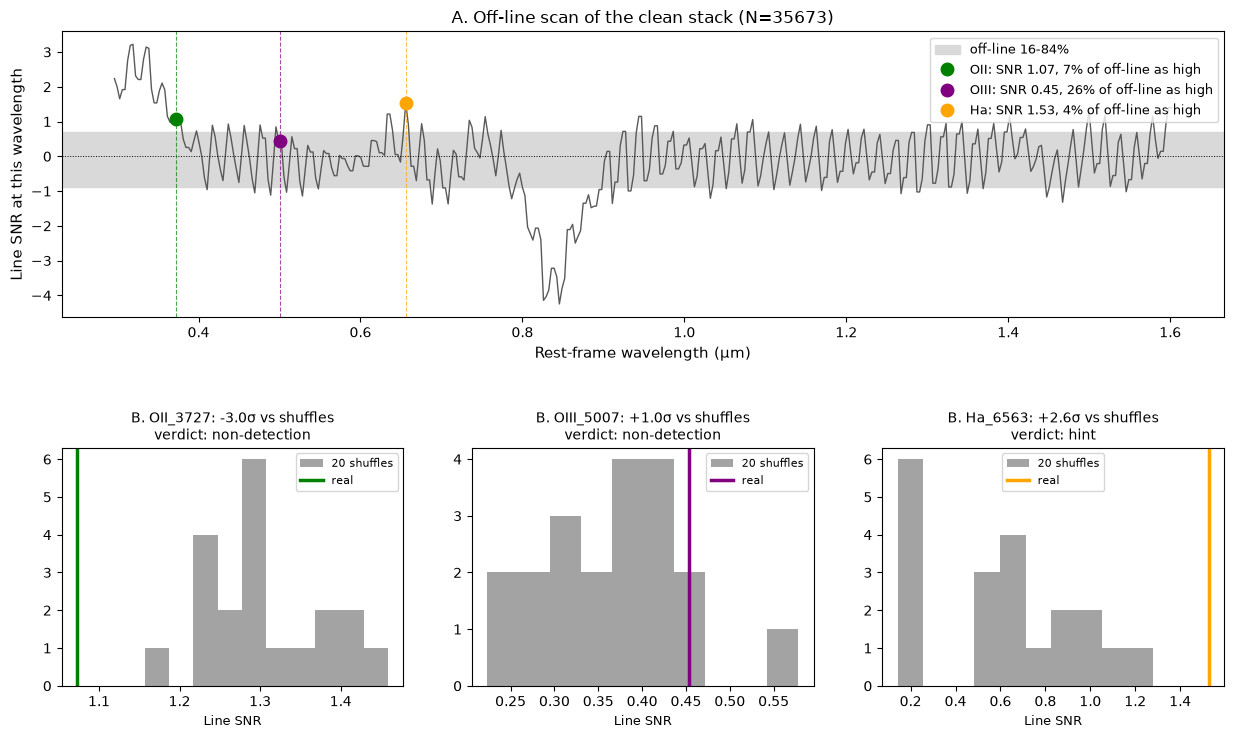

Saved: null_tests.png


In [13]:
fig = plt.figure(figsize=(15, 8.5))
gs = gridspec.GridSpec(2, len(LINES_REACHABLE), height_ratios=[1.2, 1], hspace=0.5)

ax = fig.add_subplot(gs[0, :])
ax.plot(scan_lam, scan_snr, color="0.35", lw=1.0)
ax.axhspan(off_p16, off_p84, color="0.85", label="off-line 16-84%")
ax.axhline(0, color="black", lw=0.7, ls=":")
for name, lam in LINES_REACHABLE.items():
    r = null_results[name]
    ax.axvline(lam, color=line_colors[name], lw=0.8, ls="--", alpha=0.7)
    ax.plot(lam, r["snr_clean"], "o", ms=9, color=line_colors[name],
            label=f"{name.split('_')[0]}: SNR {r['snr_clean']:.2f}, "
                  f"{100 * r['offline_frac_ge']:.0f}% of off-line as high")
ax.set_xlabel("Rest-frame wavelength (µm)", fontsize=11)
ax.set_ylabel("Line SNR at this wavelength", fontsize=11)
ax.set_title(f"A. Off-line scan of the clean stack (N={len(wav_6)})")
ax.legend(fontsize=9, loc="upper right")

for col, name in enumerate(LINES_REACHABLE):
    r = null_results[name]
    ax2 = fig.add_subplot(gs[1, col])
    ax2.hist(r["shuffle_snrs"], bins=10, color="0.6", alpha=0.9,
             label=f"{len(r['shuffle_snrs'])} shuffles")
    ax2.axvline(r["snr_clean"], color=line_colors[name], lw=2.5, label="real")
    ax2.set_title(f"B. {name}: {r['shuffle_z']:+.1f}σ vs shuffles\n"
                  f"verdict: {r['verdict']}", fontsize=10)
    ax2.set_xlabel("Line SNR", fontsize=9)
    ax2.legend(fontsize=8)

plt.savefig(os.path.join(OUTDIR, "null_tests.png"), dpi=150, bbox_inches="tight")
plt.show()
print("Saved: null_tests.png")


## Figure 4: brightness-matched control

In the 2026 run, the control was a real comparison: galaxies with partial coverage (two to four bands) at the same flux scale as the six-band sample. In DR1, 39,419 of the 39,422 LAEs have all six detectors measured, so the two-to-four "band" galaxies here are mostly galaxies whose detector segments overlap in rest-frame wavelength, not galaxies with missing coverage. I keep this figure for continuity with the earlier run, but it no longer tests what it used to. The redshift-shuffle stack above is the better control for this release.


Control: N=464 galaxies (2-4 bands, brightness-matched)
  Control raw: 78/80 bins with data


  Control clean: 78/80 bins with data


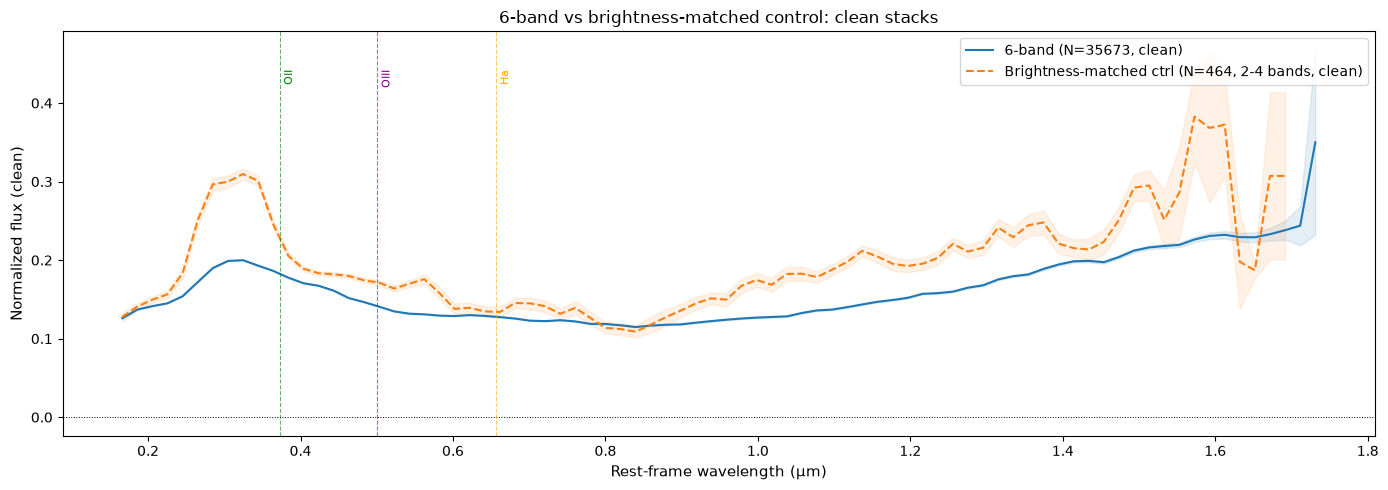

Saved: stack_control_full.png


In [14]:
norms_ctl = compute_norms(raw_ctl)
print(f"Control: N={len(wav_ctl)} galaxies (2-4 bands, brightness-matched)")

med_ctl_r, sem_ctl_r, n_ctl_r, good_ctl_r = make_stack(
    wav_ctl, raw_ctl, norms_ctl, "Control raw")
med_ctl_c, sem_ctl_c, n_ctl_c, good_ctl_c = make_stack(
    wav_ctl, cln_ctl, norms_ctl, "Control clean")

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(wav_grid[good_cln], med_cln[good_cln], color="tab:blue", lw=1.5,
        label=f"6-band (N={len(wav_6)}, clean)")
ax.fill_between(wav_grid[good_cln],
                 med_cln[good_cln] - sem_cln[good_cln],
                 med_cln[good_cln] + sem_cln[good_cln],
                 color="tab:blue", alpha=0.12)

if good_ctl_c.sum() > 0:
    ax.plot(wav_grid[good_ctl_c], med_ctl_c[good_ctl_c], color="tab:orange",
            lw=1.5, ls="--",
            label=f"Brightness-matched ctrl (N={len(wav_ctl)}, 2-4 bands, clean)")
    ax.fill_between(wav_grid[good_ctl_c],
                     med_ctl_c[good_ctl_c] - sem_ctl_c[good_ctl_c],
                     med_ctl_c[good_ctl_c] + sem_ctl_c[good_ctl_c],
                     color="tab:orange", alpha=0.10)

ax.axhline(0, color="black", lw=0.7, ls=":")
for name, lam in LINES_REACHABLE.items():
    if WAV_MIN <= lam <= WAV_MAX:
        ax.axvline(lam, color=line_colors[name], lw=0.8, ls="--", alpha=0.6)
        ax.text(lam + 0.005, ax.get_ylim()[1] * 0.90,
                name.split("_")[0], fontsize=8,
                color=line_colors[name], rotation=90, va="top")

ax.set_xlabel("Rest-frame wavelength (\u00b5m)", fontsize=11)
ax.set_ylabel("Normalized flux (clean)", fontsize=11)
ax.set_title("6-band vs brightness-matched control: clean stacks")
ax.legend(loc="upper right", fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(OUTDIR, "stack_control_full.png"), dpi=150, bbox_inches="tight")
plt.show()
print("Saved: stack_control_full.png")

## Line-to-continuum table

In [15]:
_lam_hdr   = "\u03bb(\u00b5m)"
_delta_hdr = "\u0394 L/C %"

print("=" * 135)
print(f"{'Line':<14} {_lam_hdr:>8}  "
      f"{'Raw L/C':>9} {'Raw SNR':>8}  "
      f"{'Clean L/C':>10} {'Clean SNR':>9}  "
      f"{_delta_hdr:>8}  {'p(raw/clean)':>14}  {'off-line':>8} {'shuffle':>8}  Verdict")
print("-" * 135)

comparison = {}
for name, lam in LINES_REACHABLE.items():
    status, detail = check_reachability(lam, z_min, z_max)
    lf_r, cl_r, lc_r, snr_r = extract_line(med_raw, good_both, lam)
    lf_c, cl_c, lc_c, snr_c = extract_line(med_cln, good_both, lam)

    delta_pct = ((lc_c - lc_r) / abs(lc_r) * 100
                 if (np.isfinite(lc_r) and np.isfinite(lc_c) and lc_r != 0)
                 else np.nan)

    res = bootstrap_results.get(name, {})
    p_raw = res.get("p_raw", np.nan)
    p_cln = res.get("p_cln", np.nan)
    boot_p = (f"{p_raw:.3f}/{p_cln:.3f}"
              if np.isfinite(p_raw) else "n/a")

    low_snr = (not np.isfinite(snr_r) or not np.isfinite(snr_c)
               or abs(snr_r) < MIN_SNR or abs(snr_c) < MIN_SNR)

    nr = null_results.get(name, {})
    if status == "edge_caution":
        verdict = f"EDGE ARTIFACT? ({detail})"
    elif not np.isfinite(lc_r) or not np.isfinite(lc_c):
        verdict = "no coverage"
    elif nr.get("verdict") == "DETECTION":
        verdict = "DETECTION"
    elif nr.get("verdict") == "hint":
        verdict = "hint (below detection threshold)"
    else:
        verdict = "non-detection"

    comparison[name] = dict(
        lam=lam, status=status,
        lc_raw=lc_r, snr_raw=snr_r, lf_raw=lf_r, cont_raw=cl_r,
        lc_cln=lc_c, snr_cln=snr_c, lf_cln=lf_c, cont_cln=cl_c,
        delta_pct=delta_pct, verdict=verdict, low_snr=low_snr,
        p_raw=p_raw, p_cln=p_cln,
        offline_frac=nr.get("offline_frac_ge", np.nan),
        shuffle_z=nr.get("shuffle_z", np.nan),
    )

    def f(v, w=9, d=4):
        return f"{v:{w}.{d}f}" if np.isfinite(v) else f"{'n/a':>{w}}"

    print(f"{name:<14} {lam:>8.4f}  "
          f"{f(lc_r):>9} {f(snr_r,8,2):>8}  "
          f"{f(lc_c):>10} {f(snr_c,9,2):>9}  "
          f"{f(delta_pct,8,1):>8}  {boot_p:>14}  "
          f"{f(nr.get('offline_frac_ge', np.nan),8,3)} "
          f"{f(nr.get('shuffle_z', np.nan),7,1)}σ  {verdict}")

print("=" * 135)
print(f"Bootstrap p-values: p_raw/p_clean  "
      f"({N_BOOTSTRAP} resamples, N={len(wav_6)} galaxies)")
print("Verdicts come from the null tests: off-line = fraction of off-line positions "
      "with SNR at least as high; shuffle = margin over the redshift-shuffled stacks.")
print("Bootstrap p-values are shown for reference (see the caveat in the bootstrap section).")


Line              λ(µm)    Raw L/C  Raw SNR   Clean L/C Clean SNR   Δ L/C %    p(raw/clean)  off-line  shuffle  Verdict
---------------------------------------------------------------------------------------------------------------------------------------
OII_3727         0.3727     0.0700     1.51      0.1153      1.07      64.7     0.000/0.000     0.070    -3.0σ  non-detection
OIII_5007        0.5007     0.0314     0.36      0.0450      0.45      43.1     0.000/0.000     0.261     1.0σ  non-detection
Ha_6563          0.6563     0.0885     0.72      0.0507      1.53     -42.7     0.000/0.000     0.043     2.6σ  hint (below detection threshold)
Bootstrap p-values: p_raw/p_clean  (1000 resamples, N=35673 galaxies)
Verdicts come from the null tests: off-line = fraction of off-line positions with SNR at least as high; shuffle = margin over the redshift-shuffled stacks.
Bootstrap p-values are shown for reference (see the caveat in the bootstrap section).


## Derived line ratios

These are printed for completeness only. With no line detected, the ratios are dominated by noise and should not be interpreted physically.

In [16]:
def safe_r(a, b):
    return a / b if (np.isfinite(a) and np.isfinite(b) and b != 0) else np.nan

def fmt(v, w=10, d=3):
    return f"{v:{w}.{d}f}" if np.isfinite(v) else f"{'n/a':>{w}}"

oiii_r = comparison["OIII_5007"]["lc_raw"]; oiii_c = comparison["OIII_5007"]["lc_cln"]
oii_r  = comparison["OII_3727"]["lc_raw"];  oii_c  = comparison["OII_3727"]["lc_cln"]
ha_r   = comparison["Ha_6563"]["lc_raw"];   ha_c   = comparison["Ha_6563"]["lc_cln"]

ratios = [
    ("O32=[OIII]/[OII]",
     safe_r(oiii_r,oii_r), safe_r(oiii_c,oii_c), "ionization parameter"),
    ("[OIII]/H\u03b1",
     safe_r(oiii_r,ha_r),  safe_r(oiii_c,ha_c),  "ionization state"),
    ("H\u03b1/[OII]",
     safe_r(ha_r,oii_r),   safe_r(ha_c,oii_c),   "SFR / dust proxy"),
]

_dh = "\u0394%"
print("\n\u2500\u2500 Derived ratios (report only if BOTH constituent lines detected) \u2500")
print(f"  {'Ratio':<22} {'Raw':>10}  {'Clean':>10}  {_dh:>8}  Note")
print("  " + "-" * 68)

for label, r_raw, r_cln, meaning in ratios:
    if np.isfinite(r_raw) and np.isfinite(r_cln) and r_raw != 0:
        delta = (r_cln - r_raw) / abs(r_raw) * 100
        flag  = " UNSTABLE" if abs(delta) > STABILITY_THRESHOLD * 100 else ""
    else:
        delta, flag = np.nan, ""
    print(f"  {label:<22} {fmt(r_raw)}  {fmt(r_cln)}  "
          f"{fmt(delta,8,1)}{flag}   {meaning}")



── Derived ratios (report only if BOTH constituent lines detected) ─
  Ratio                         Raw       Clean        Δ%  Note
  --------------------------------------------------------------------
  O32=[OIII]/[OII]            0.449       0.390     -13.1   ionization parameter
  [OIII]/Hα                   0.355       0.887     150.0 UNSTABLE   ionization state
  Hα/[OII]                    1.265       0.440     -65.2 UNSTABLE   SFR / dust proxy


## Upper limits

For each line that is not detected, I report an approximate $3\sigma$ upper limit on $L/C$ from the off-line scan: the scatter of the line statistic at wavelengths with no line, converted to $L/C$ with each line's own continuum and noise level, added to the measured value. In the 2026 run I scaled the limits from the bootstrap spread instead. That spread shrinks as $N$ grows while the systematic floor does not, so at DR1 depth it would give limits that are far too optimistic. These limits set the baseline that a better zodiacal model (or a future release) needs to beat.


In [17]:
print("\n── 3σ Upper Limits (lines not detected) ──────")
_ul_hdr = "3σ UL on L/C"
print(f"  {'Line':<14} {_ul_hdr:>16}  Note")
print("  " + "-" * 60)
upper_limits = {}
for name, d in comparison.items():
    if d.get("status") != "reachable" or d.get("verdict") == "DETECTION":
        continue
    lc_c, snr_c = d.get("lc_cln", np.nan), d.get("snr_cln", np.nan)
    if np.isfinite(lc_c) and np.isfinite(snr_c) and snr_c != 0:
        lc_per_snr = abs(lc_c / snr_c)       # converts SNR units to L/C for this line
        ul_3sig = max(lc_c, 0.0) + 3 * off_sigma * lc_per_snr
        upper_limits[name] = float(ul_3sig)
        print(f"  {name:<14} {ul_3sig:>16.3f}  (3σ, off-line scatter)")
    else:
        print(f"  {name:<14} {'n/a':>16}")
print()
print(f"Off-line scatter: σ = {off_sigma:.2f} in SNR units "
      f"(half the 16-84% range of {len(off_snr)} positions).")



── 3σ Upper Limits (lines not detected) ──────
  Line               3σ UL on L/C  Note
  ------------------------------------------------------------
  OII_3727                  0.370  (3σ, off-line scatter)
  OIII_5007                 0.280  (3σ, off-line scatter)
  Ha_6563                   0.130  (3σ, off-line scatter)

Off-line scatter: σ = 0.79 in SNR units (half the 16-84% range of 345 positions).


## Summary

In [18]:
print("\n" + "=" * 70)
print("  FINAL VERDICT: FULL POPULATION ANALYSIS")
print("=" * 70)

reach = {n: d for n, d in comparison.items() if d.get("status") == "reachable"}
detections = {n: d for n, d in reach.items() if d["verdict"] == "DETECTION"}
hints      = {n: d for n, d in reach.items() if d["verdict"].startswith("hint")}
non_detect = {n: d for n, d in reach.items()
              if n not in detections and n not in hints}


def _line(n, d):
    ul = upper_limits.get(n)
    ul_s = f"  3σ UL={ul:.3f}" if ul is not None else ""
    return (f"  {n:<14} SNR={d['snr_cln']:.2f}  off-line={d['offline_frac']:.3f}  "
            f"shuffle={d['shuffle_z']:+.1f}σ{ul_s}")


for title, group in [("DETECTIONS", detections),
                     ("Hints (below detection threshold)", hints),
                     ("Non-detections", non_detect)]:
    if group:
        print(f"\n{title}:")
        for n, d in group.items():
            print(_line(n, d))

print(f"\n  N galaxies (6-band subset): {len(wav_6)}")
print(f"  N galaxies (control):        {len(wav_ctl)}")
print(f"  Bootstrap resamples:         {N_BOOTSTRAP}")
print(f"  Redshift shuffles:           {N_SHUFFLE}")
print(f"  ZODI fraction:               {zodi_global:.3f}")
print(f"  Stack grid:                  {WAV_MIN:.4f}–{WAV_MAX:.4f} µm")
print(f"  Mean redshift (6-band):      {np.nanmean(zs_6):.3f}")

print()
if detections:
    print("At least one line passes both null tests in the ZODI-subtracted stack.")
else:
    print("No line is detected after ZODI subtraction.")
    if hints:
        print("Hints are listed above; they are below the detection threshold.")
    print(f"Zodiacal light makes up ~{100*zodi_global:.0f}% of the raw signal at these positions.")
    print("The upper limits above are the main quantitative result at this depth.")
print("=" * 70)



  FINAL VERDICT: FULL POPULATION ANALYSIS

Hints (below detection threshold):
  Ha_6563        SNR=1.53  off-line=0.043  shuffle=+2.6σ  3σ UL=0.130

Non-detections:
  OII_3727       SNR=1.07  off-line=0.070  shuffle=-3.0σ  3σ UL=0.370
  OIII_5007      SNR=0.45  off-line=0.261  shuffle=+1.0σ  3σ UL=0.280

  N galaxies (6-band subset): 35673
  N galaxies (control):        464
  Bootstrap resamples:         1000
  Redshift shuffles:           20
  ZODI fraction:               0.851
  Stack grid:                  0.1661–1.7312 µm
  Mean redshift (6-band):      2.515

No line is detected after ZODI subtraction.
Hints are listed above; they are below the detection threshold.
Zodiacal light makes up ~85% of the raw signal at these positions.
The upper limits above are the main quantitative result at this depth.


## Machine-readable summary

Written to `summary.json` in the output directory so runs on different SPHEREx releases can be compared with `python pipeline/compare_runs.py`.

In [19]:
def _f(x):
    x = float(x) if x is not None else np.nan
    return x if np.isfinite(x) else None

summary = {
    "date": datetime.datetime.now().isoformat(timespec="seconds"),
    "cache_file": os.path.basename(CACHE_FILE),
    "n_with_coverage": len(cache),
    "n_six_band": len(wav_6),
    "n_control": len(wav_ctl),
    "n_bootstrap": N_BOOTSTRAP,
    "n_shuffle": N_SHUFFLE,
    "offline_scatter_snr": _f(off_sigma),
    "zodi_fraction": _f(zodi_global),
    "mean_z_six_band": _f(np.nanmean(zs_6)),
    "lines": {
        name: {
            "status": d.get("status"),
            "snr_clean": _f(d.get("snr_cln")),
            "p_clean": _f(d.get("p_cln")),
            "p_raw": _f(d.get("p_raw")),
            "lc_clean": _f(d.get("lc_cln")),
            "offline_frac_ge": _f(d.get("offline_frac")),
            "shuffle_z": _f(d.get("shuffle_z")),
            "ul_3sigma": upper_limits.get(name),
            "verdict": d.get("verdict"),
        }
        for name, d in comparison.items()
    },
}
with open(os.path.join(OUTDIR, "summary.json"), "w") as fh:
    json.dump(summary, fh, indent=2)
print(json.dumps(summary, indent=2))

{
  "date": "2026-11-23T14:00:52",
  "cache_file": "sed_cache_full.pkl",
  "n_with_coverage": 39403,
  "n_six_band": 35673,
  "n_control": 464,
  "n_bootstrap": 1000,
  "n_shuffle": 20,
  "offline_scatter_snr": 0.7911059028664198,
  "zodi_fraction": 0.8507850393047267,
  "mean_z_six_band": 2.514645903705264,
  "lines": {
    "OII_3727": {
      "status": "reachable",
      "snr_clean": 1.0728102230765804,
      "p_clean": 0.0,
      "p_raw": 0.0,
      "lc_clean": 0.11531285586154348,
      "offline_frac_ge": 0.06956521739130435,
      "shuffle_z": -2.988970312992445,
      "ul_3sigma": 0.3704130002845888,
      "verdict": "non-detection"
    },
    "OIII_5007": {
      "status": "reachable",
      "snr_clean": 0.4535950064843643,
      "p_clean": 0.0,
      "p_raw": 0.0,
      "lc_clean": 0.04498544341965279,
      "offline_frac_ge": 0.2608695652173913,
      "shuffle_z": 1.0198293922840183,
      "ul_3sigma": 0.28036005727297403,
      "verdict": "non-detection"
    },
    "Ha_6563":

## Discussion

### The 2026 run ($N = 565$)

Although a non-detection was not the result I was hoping for, I believe it was the correct one, and it was more informative than a marginal hint would have been. Scaling the pilot's $p = 0.092$ for Hα to $N = 565$ predicted roughly $p \approx 0.01$ if the signal were real. Instead, the clean-stack $p$-value rose to 0.759, which told me the pilot hint was most likely noise.

Furthermore, the contrast between the raw and clean bootstrap distributions was itself useful. [O II] and Hα looked significant in the raw stack ($p = 0.001$ and $0.010$) but centered on zero after subtraction. This brought to light how easily zodiacal structure can masquerade as line emission in early SPHEREx stacks, and why any analysis must report both versions side by side.

### SPHEREx DR1 ($N = 35{,}673$)

Going from 565 to 35,673 galaxies changed what this analysis is limited by. The first DR1 pass reported all three lines as detections at $p < 0.001$, and none of them were. The bootstrap had quietly stopped measuring what I needed: once the sample is this large, the stack is so stable under resampling that any fixed residual looks significant. The null tests are what separate a line from a feature of the continuum or of the zodiacal model, and [O II] makes the point clearly, since its "signal" gets stronger when the redshifts are shuffled.

Hα is the one line that does not behave like a pure artifact. It sits above 96% of the off-line positions and 2.6 shuffle-sigma above the shuffled stacks, and it is the same line that hinted in the pilot. That is not a detection, and with three lines tested a hint at this level is expected by chance about 14% of the time, but it is the first thing I would check in the next release.

The most important result, though, is that the upper limits did not improve. With 63 times more galaxies, the limits are no tighter than in 2026, so this stack is now limited by systematics, not by sample size. Two directions follow from that. First, each detector band here was measured from one of the roughly 55 available exposures (`EPOCHS_PER_BAND = 1`). Zodiacal light changes with viewing geometry, so averaging over many epochs may average down exactly the residuals that set the current floor. Second, a smoother continuum model under each line would reduce the curvature that produced the [O II] false positive.

Two results here should carry over to other SPHEREx work: the ~85% zodiacal fraction at HETDEX LAE positions (0.82 in 2026, 0.85 in DR1), and the lesson that bootstrap significance is not a detection criterion for very large stacks. The band-count selection effect from 2026 turned out to be a product of partial coverage, which is worth knowing for anyone stacking early SPHEREx data.
